# What data does GLHMM need?

GLHMM works with time series data. For example, fMRI BOLD signals or MEG recordings. The data should be organised as a 2D array where rows are timepoints and columns are brain regions or channels

 you have a single recording session, you can pass it directly. If you have multiple subjects or sessions, you concatenate them into one array and tell the model where each session starts and ends using an ```indices``` array:

In [1]:
import numpy as np
indices = np.array([
    [0,1000],
    [1000, 1800]
    ])

# example fits 6 state model to a single session of simulated data

from glhmm import glhmm

Y = np.random.randn(5000,80) # 5000 timepoint, 80 channels

hmm = glhmm.glhmm(K = 6, covtype='full', model_mean= 'no', model_beta='no')

# train 
Gamma, Xi, fe = hmm.train(Y=Y)

print(Gamma.shape)
print(f"free energy: {fe[-1]:.2f}" )

Init repetition 1 free energy = 749557.7617768613
Init repetition 2 free energy = 748483.906152562
Init repetition 3 free energy = 749482.799470121
Init repetition 4 free energy = 748620.4443200477
Init repetition 5 free energy = 749131.5608342475
Best repetition: 2
Cycle 1 free energy = 748229.5204429503
Cycle 2 free energy = 747957.1110094198
Cycle 3, free energy = 747702.603773689, relative change = 0.48301230645743315
Cycle 4, free energy = 747484.9095955135, relative change = 0.29235966535392277
Cycle 5, free energy = 747295.0203034923, relative change = 0.20319878403795816
Cycle 6, free energy = 747091.7407325782, relative change = 0.17866338190160438
Cycle 7, free energy = 746866.3688583144, relative change = 0.16533148389659655
Cycle 8, free energy = 746599.6763281222, relative change = 0.16363069803170768
Cycle 9, free energy = 746285.6989583521, relative change = 0.16152582542061836
Cycle 10, free energy = 746028.3079715383, relative change = 0.116931459437309
Cycle 11, free 

# Try first HMM

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from glhmm import glhmm, preproc, utils, graphics, statistics

path =  "C:\\Users\\pipo\\Datasets-Docs\\GLHMM_example_dataset\\"
Y = np.load(path+'Simulation_data_numpy\\data_sim.npy')
n_subjects = 20
Y = Y[:, :n_subjects, :]
n_timepoints = Y.shape[0]

Y_2d = statistics.get_concatenate_subjects(Y)       # (n_subjects * n_timepoints, n_features)
indices = statistics.get_indices_timestamp(n_timepoints, n_subjects)

print(f'Data   : {Y_2d.shape}')
print(f'Indices: {indices.shape}, first rows {indices[:2].tolist()}')

## preprocess
Y_preproc, indices, log = preproc.preprocess_data(Y_2d, indices, standardise=True)

print(f'Y_preproc   : {Y_preproc.shape}')
print(f'ndices   : {indices.shape}')

Data   : (96000, 50)
Indices: (20, 2), first rows [[0, 4800], [4800, 9600]]
Y_preproc   : (96000, 50)
indices   : (20, 2)


**Set up and train the model**

Training took 26 cycles
Gamma: (96000, 6)  (timepoints x states)


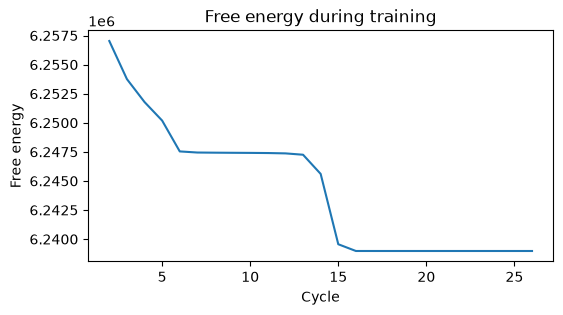

In [ ]:
hmm = glhmm.glhmm(K=6, covtype='full', model_mean='state', model_beta='no')
Gamma, Xi, fe = hmm.train(Y=Y_preproc, indices=indices, options={'verbose': True})

print(f'Training took {len(fe)} cycles')
print(f'Gamma: {Gamma.shape}  (timepoints x states)')


plt.figure(figsize=(6, 3))
plt.plot(np.arange(2, len(fe) + 1), fe[1:])
plt.xlabel('Cycle')
plt.ylabel('Free energy')
plt.title('Free energy during training')
plt.show()

**Discover at the states**

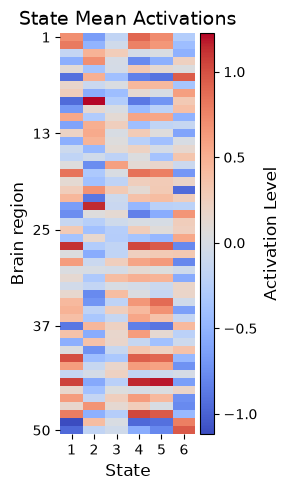

In [12]:
graphics.plot_state_means_activations(hmm.get_means())
plt.show()

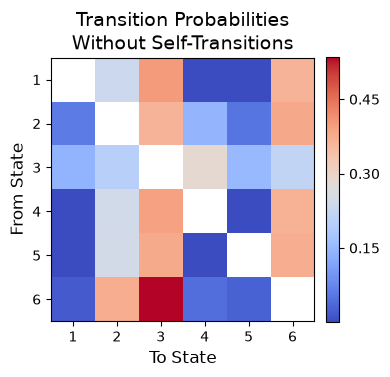

In [13]:
graphics.plot_transition_matrix(hmm.get_P(), with_self_transitions=False)
plt.show()

In [15]:
hmm.get_P().shape

(6, 6)

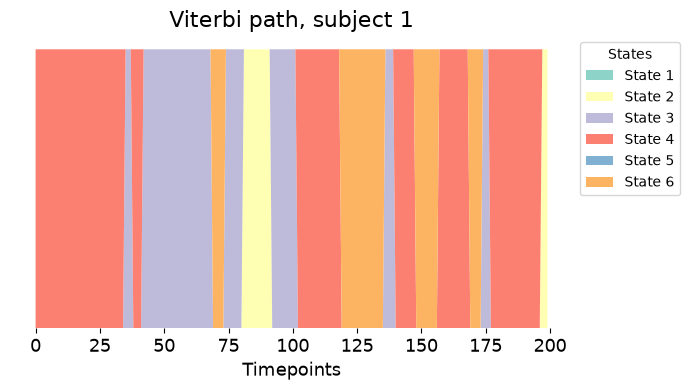

In [16]:
vpath = hmm.decode(None, Y_preproc, indices, viterbi=True)   # one column per state, 1 for the active state
graphics.plot_vpath(vpath[:200], title='Viterbi path, subject 1')
plt.show()

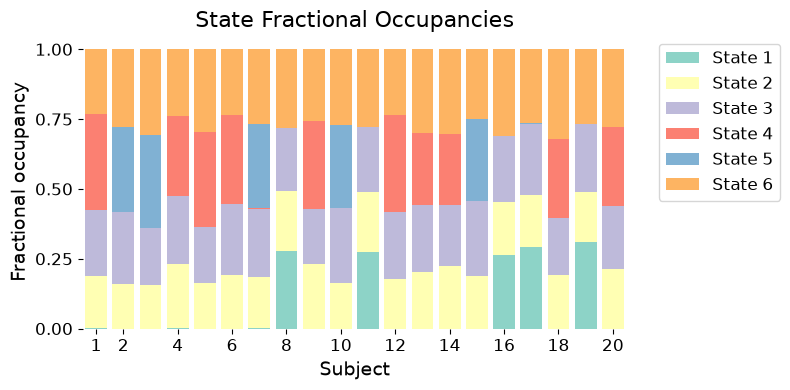

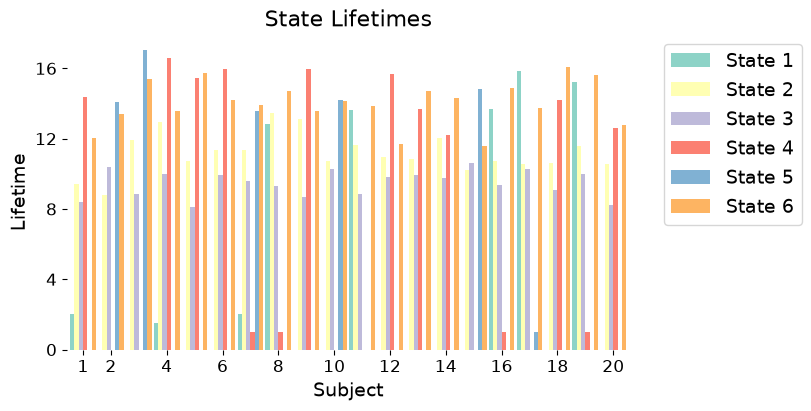

In [17]:
FO = utils.get_FO(Gamma, indices)                            # subjects x states
mean_LT, median_LT, max_LT = utils.get_life_times(vpath, indices)

graphics.plot_FO(FO)
plt.show()
graphics.plot_state_lifetimes(mean_LT)
plt.show()